# Day 22: Deep Learning Mini-Project & Checkpoint

Today **you** build and train a small neural network, alone, from start to end.

**Checkpoint:** at the end of today you can say:
> "I understand what this code is doing, and I can train a small neural network."

| Part | What you do | Time |
|---|---|---|
| A | Read code and explain each line | 25 min |
| B | Mini-project: predict exam results | 75 min |
| C | Experiments: change settings, compare | 25 min |
| D | Answer 6 short questions | 15 min |
| ✅ | Checkpoint list | 5 min |

**Rules:** You can look at your old notebooks. Ask the teacher only after you try for 5 minutes.

In [1]:
import numpy as np                                     # arrays of numbers
import pandas as pd                                    # tables (read CSV files)
import matplotlib.pyplot as plt                        # charts
import torch                                           # PyTorch: tensors + training
from torch import nn                                   # layers, ReLU, loss functions
from sklearn.model_selection import train_test_split   # split into train / validation / test
from sklearn.preprocessing import StandardScaler       # make columns the same scale

---
# Part A: Read the code and explain it

This code trains a small network on **loans.csv**: will the bank **approve** the loan (1) or not (0)?

**Your task:** run it. Then, in the next cell, write a short comment **after every line**: what does this line do?

In [2]:
loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount"]].values
y = loans[["approved"]].values

X = StandardScaler().fit_transform(X)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(100):
    guess = model(X)
    loss = loss_fn(guess, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("final loss:", round(loss.item(), 3))

final loss: 0.452


In [3]:
# Copy the code here and write a comment after EVERY line.
# Example:  loans = pd.read_csv("loans.csv")    # read the table from the file

loans = pd.read_csv("loans.csv")                         # loads the loans table from the file
X = loans[["monthly_income", "loan_amount"]].values      # assigns monthly_income and loan_amount as input features to X 
y = loans[["approved"]].values                           # assigns the approved column as the target value

X = StandardScaler().fit_transform(X)                    # scales the input values to the same range 
X = torch.tensor(X, dtype=torch.float32)                 # converts input to a floating point pytorch tensor
y = torch.tensor(y, dtype=torch.float32)                 # converts target to a floating point pytorch tensor

torch.manual_seed(42)                                    # sets the same random values everytime
model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())    # sequential converts the layers into rows, nn.Linear(2, 8) 2 inputs and 8 neurons, nn.ReLU() applies the activation function on the neurons, nn.Linear(8, 1) 8 inputs (The outputs of the previous layers) and 1 output, nn.Sigmoid turns the output into a classification output like yes or no.
loss_fn = nn.BCELoss()                                             # initializes the built in Binary Cross Entropy loss function  
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)          # optimizes the learned parameters and adds the learning rate as 0.01

for epoch in range(100):                           # epoch gives the all training paramters as batches. range(100) gives the values 100 times for training
    guess = model(X)                               # gives the input values to the model                             
    loss = loss_fn(guess, y)                       # computes binary cross entropy loss between predicted and actual values
    optimizer.zero_grad()                          # clears the stored gradients to prevent mixing
    loss.backward()                                # starts backpropagation, calculates the gradient descent values and it tells where to update the weight and bias
    optimizer.step()                               # updates the new weight and bias

print("final loss:", round(loss.item(), 3))        # prints the loss value rounded to 3 decimal points

final loss: 0.452


**✏️ Questions about Part A** (write your answer in the cell below each one)

1. Why does this model end with `nn.Sigmoid()`?
2. Why do we use `BCELoss` here?
3. In Part B we predict **3** results. Which last layer and which loss will we use there?

*Your answers:*

1. It changes the output to a probability between 0 and 1 so we can guess yes or no
2. It calculates the loss for binary classification problems.
3. The last layer will be nn.Linear(inputs, 3) and the cross entropy loss function will be used as the there are multiple classes as the output

---
# Part B: Mini-project: predict exam results

A college in Lahore wants to know early which students need help.
For **400 students** they have 5 numbers and the final **result**.

| Column | Meaning |
|---|---|
| `study_hours` | hours of study per day (0 to 6) |
| `attendance_pct` | attendance in % (40 to 100) |
| `assignments_done` | assignments done, out of 10 |
| `sleep_hours` | hours of sleep per night |
| `phone_hours` | hours on the phone per day |
| `result` | **0 = Fail, 1 = Pass, 2 = Distinction** |

**Goal:** train a network that guesses `result`. Then check it on the test students.

These 2 classes are the same as in class. **Run this cell, do not change it.**

In [4]:
class Net(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs):
        super().__init__()                          # start the nn.Module part
        self.hidden = nn.Linear(n_inputs, n_hidden) # input → hidden (weights + biases)
        self.relu = nn.ReLU()                       # activation: negative → 0
        self.output = nn.Linear(n_hidden, n_outputs)# hidden → output

    def forward(self, x):
        return self.output(self.relu(self.hidden(x)))


class Trainer:
    def __init__(self, model, loss_fn, lr):
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        self.train_losses, self.val_losses = [], []

    def fit(self, X_train, y_train, X_val, y_val, epochs):
        for epoch in range(epochs):
            loss = self.loss_fn(self.model(X_train), y_train)   # 1. guess + 2. how wrong
            self.optimizer.zero_grad()                          # 3. clear old blame
            loss.backward()                                     # 4. find blame (backprop)
            self.optimizer.step()                               # 5. fix (gradient descent)
            self.train_losses.append(loss.item())
            with torch.no_grad():                               # mock exam: check only
                self.val_losses.append(self.loss_fn(self.model(X_val), y_val).item())

    def predict(self, X):
        with torch.no_grad():
            return self.model(X)

    def plot(self):
        plt.plot(self.train_losses, label="train (homework)")
        plt.plot(self.val_losses, label="validation (mock exam)")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()

## Step 1: Load and look

- Read `exam_results.csv` into `exams`.
- Print the first 5 rows and the shape.
- Count how many students are in each result with `.value_counts()`.

In [5]:
# your code here
exams = pd.read_csv("exam_results.csv")
print(exams.head())
print(exams.shape)
print(exams["result"].value_counts())

   study_hours  attendance_pct  assignments_done  sleep_hours  phone_hours  \
0          3.8              60                 6          8.3          3.5   
1          5.4              96                10          8.4          2.0   
2          4.7              49                 6          7.1          5.7   
3          1.4              71                 1          6.6          5.8   
4          1.8              45                10          5.0          6.6   

   result  
0       1  
1       2  
2       1  
3       0  
4       0  
(400, 6)
result
1    180
0    140
2     80
Name: count, dtype: int64


## Step 2: X and y

- `X` = the 5 input columns (everything **except** `result`). Hint: `exams.drop(columns="result")`
- `y` = the `result` column.
- Use `.values` on both.

In [6]:
# your code here
X = exams.drop(columns="result").values
y = exams[["result"]].values

## Step 3: Split 60 / 20 / 20

Homework (train), mock exam (validation), final exam (test). Use `random_state=42` both times.

In [7]:
# your code here
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)
print("train:", len(X_train), " validation:", len(X_val), " test:", len(X_test))

train: 240  validation: 80  test: 80


## Step 4: Scale

- `attendance_pct` is 40 to 100, `sleep_hours` is 4 to 9. Big numbers would push the weights too much.
- Make a `StandardScaler`. **Fit it on train only**, then transform train, val and test.
- Why train only? The test students are the "final exam". We must not peek at them.

In [8]:
# your code here
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

## Step 5: Tensors

- Inputs → `torch.float32` (decimals).
- Answers → `torch.long` (whole numbers), because `CrossEntropyLoss` wants the class number 0, 1, 2.

In [9]:
# your code here
X_train_t = torch.tensor(X_train_s, dtype=torch.float32) 
X_val_t = torch.tensor(X_val_s, dtype=torch.float32) 
X_test_t = torch.tensor(X_test_s, dtype=torch.float32) 
y_train_t = torch.tensor(y_train, dtype=torch.long).squeeze(1)
y_val_t = torch.tensor(y_val, dtype=torch.long).squeeze(1)
y_test_t = torch.tensor(y_test, dtype=torch.long).squeeze(1)

## Step 6: Build and train

- Model: `Net` with **5 inputs, 16 hidden, 3 outputs**. Write `torch.manual_seed(42)` first.
- Loss: `nn.CrossEntropyLoss()`. Learning rate `0.01`.
- Train **100 epochs** with `Trainer`, then `.plot()` the losses.

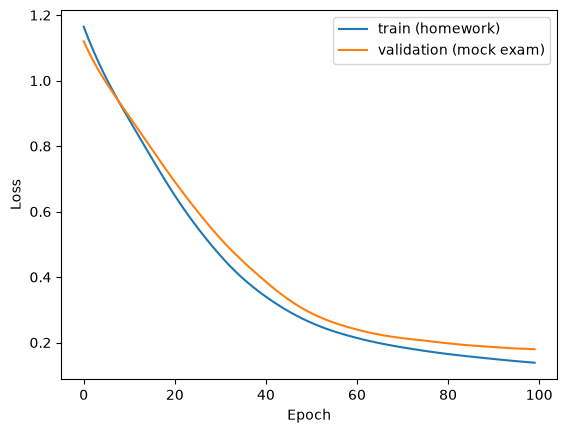

In [10]:
# your code here
torch.manual_seed(42)
model = Net(n_inputs=5, n_hidden=16, n_outputs=3)
trainer = Trainer(model, nn.CrossEntropyLoss(), lr=0.01)
trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)
trainer.plot()

**✏️ Look at your plot:** do both lines go down? Does the validation line stop going down or go up at the end?

*Your answer:* Yes, both lines go down and the validation line goes down at the end as well

## Step 7: Evaluate

- Guess for the **train** and **test** students: `trainer.predict(...)`, then `.argmax(dim=1)`.
- Accuracy = correct ÷ total. Print both.
- Make a table of real vs guessed with `pd.crosstab(y_test, test_guess)`.

In [11]:
# your code here
train_guess = trainer.predict(X_train_t).argmax(dim=1)
test_guess = trainer.predict(X_test_t).argmax(dim=1)

train_acc = (train_guess == y_train_t).float().mean().item() * 100
test_acc = (test_guess == y_test_t).float().mean().item() * 100

print("Train Accuracy:", round(train_acc, 1), "%")
print("Test Accuracy:", round(test_acc, 1), "%")

pd.crosstab(y_test_t, test_guess)

Train Accuracy: 96.2 %
Test Accuracy: 82.5 %


col_0,0,1,2
row_0,,,
0,25,0,0
1,6,30,6
2,0,2,11


**✏️ Questions:**
1. Is test accuracy lower than train accuracy? What does that mean?
2. In the table, which mistakes happen most? (Fail ↔ Pass, Pass ↔ Distinction, or Fail ↔ Distinction?)

*Your answers:*

1. Yes, test accuracy is lower than train accuracy. This means the model memorized the training data.
2. The mistakes that happen most are Fail ↔ Pass (6 Pass students were guessed as Fail) and Pass ↔ Distinction (6 Pass students were guessed as distinction)

## Step 8: Predict for new students

| Name | study | attendance | assignments | sleep | phone |
|---|---|---|---|---|---|
| Ali | 5.0 | 90 | 9 | 7.5 | 1.0 |
| Sara | 1.0 | 55 | 2 | 5.0 | 6.0 |

- Put them in a table (2 rows × 5 numbers).
- **Scale with the same `scaler`** (only `.transform`).
- Tensor → `trainer.predict` → `torch.softmax(..., dim=1)` to see the chances.

In [12]:
# your code here
new_students = pd.DataFrame({
    'study_hours': [5.0, 1.0],
    'attendance_pct': [90, 55],
    'assignments_done': [9, 2],
    'sleep_hours': [7.5, 5.0],
    'phone_hours': [1.0, 6.0]
}).values

new_students_s = scaler.transform(new_students)
new_students_t = torch.tensor(new_students_s, dtype=torch.float32)

student_guess = trainer.predict(new_students_t)
chances = torch.softmax(student_guess, dim=1)

for name, probability in zip(["Ali", "Sara"], chances):
    fail = probability[0].item() * 100
    passed = probability[1].item() * 100
    dist = probability[2].item() * 100
    print(f"{name} -> Fail: {fail:.1f}%, Pass: {passed:.1f}%, Distinction: {dist:.1f}%")

Ali -> Fail: 0.0%, Pass: 0.0%, Distinction: 100.0%
Sara -> Fail: 100.0%, Pass: 0.0%, Distinction: 0.0%


---
# Part C: Experiments

One setting at a time. Run `run(...)` and **write the numbers in the table**.

In [13]:
def run(n_hidden=16, lr=0.01, epochs=100):
    torch.manual_seed(42)
    model = Net(5, n_hidden, 3)
    trainer = Trainer(model, nn.CrossEntropyLoss(), lr=lr)
    trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=epochs)
    train_acc = (trainer.predict(X_train_t).argmax(dim=1).numpy() == y_train).mean()
    test_acc = (trainer.predict(X_test_t).argmax(dim=1).numpy() == y_test).mean()
    print(f"hidden={n_hidden}, lr={lr}, epochs={epochs} → train {train_acc:.1%}, test {test_acc:.1%}")

run()   # our model from Part B

hidden=16, lr=0.01, epochs=100 → train 35.4%, test 36.6%


In [14]:
# Try these one by one:
# run(lr=0.001)
# run(lr=0.1)
# run(n_hidden=4)
# run(n_hidden=64)
# run(epochs=20)
# run(epochs=300)

| Change | Train acc | Test acc | What happened? |
|---|---|---|---|
| normal (16, 0.01, 100) |35.4%|36.6%|Model is guessing randomly and not learning patterns yet. |
| lr = 0.001 |33.9%|35.5%|Learning rate is too small, updates are too slow. |
| lr = 0.1 |35.5%|36.5%|Learning rate is too big, jumps over optimal weights.|
| hidden = 4 |35.6%|37.6%|Too few hidden neurons to catch relationships.|
| hidden = 64 |35.4%|37.7%|Bigger network still stuck near random accuracy.|
| epochs = 20 |35.1%|36.1%|Stopped too early before learning started.|
| epochs = 300 |35.4%|38.0%|Trained longer but barely improved over random guess.|

---
# Part D: Short questions

Answer in 1–2 lines each.

1. What does **one epoch** mean?
2. What do `loss.backward()` and `optimizer.step()` do?
3. Why do we split off **test** data and never train on it?
4. Why did we **scale** the columns?
5. Why is there **no softmax layer** in our `Net`?
6. Train 96%, test 82%. What is the name for this gap, and give one way to make it smaller.

*Your answers:*

1. One epoch means one complete pass of the training loop through the entire training dataset.
2. loss.backward() calculates the gradients and optimizer.step() updates the weights one small step downhill.
3. To evaluate the model on completely new, unseen data to make sure it learned patterns instead of just memorizing training answers.
4. Because features have different ranges (like attendance 40–100 vs phone hours 0–6). Scaling prevents columns with larger numbers from dominating the learning process.
5. Because PyTorch's nn.CrossEntropyLoss() automatically applies Softmax internally during training
6. This gap is called Overfitting. One way to make it smaller is to reduce the hidden layer size or train for fewer epochs.

---
# ✅ Checkpoint

Tick each line only if it is true. Show the teacher.

- ✅ I can explain what every line of the Part A code does.
- ✅ I can load a CSV and make X and y.
- ✅ I can split into train / validation / test and scale with train only.
- ✅ I can make tensors (float32 for inputs, long for classes).
- ✅ I can build a `Net`, train it with `Trainer`, and read the loss plot.
- ✅ I can work out accuracy on test data.
- ✅ I know when to use Sigmoid + BCELoss and when to use CrossEntropyLoss.
- ✅ I can predict for a new person (scale first!).

---
# 🏠 Problem

Same steps, **yes/no** problem: will the bank approve the loan? Use `loans.csv`.

1. X = `monthly_income`, `loan_amount`, `years_in_job`, `has_defaulted_before`. y = `approved`.
2. Split 60 / 20 / 20, scale with train only.
3. Tensors: X **float32**, y **float32** with shape (n, 1). (BCELoss wants decimals.)
4. Model: `nn.Sequential(nn.Linear(4, 8), nn.ReLU(), nn.Linear(8, 1), nn.Sigmoid())`, loss `nn.BCELoss()`, 100 epochs.
5. Guess = chance > 0.5. Print the test accuracy.
6. Write 2 lines: what changed compared with the exam project, and why?

In [16]:
# your code here
# Step 1
loans = pd.read_csv("loans.csv")
print(loans.head())
X = loans.drop(columns="approved").values
y = loans[["approved"]].values

# Step 2
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)
print("train:", len(X_train), " validation:", len(X_val), " test:", len(X_test))

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# Step 3
# your code here
X_train_t = torch.tensor(X_train_s, dtype=torch.float32) 
X_val_t = torch.tensor(X_val_s, dtype=torch.float32) 
X_test_t = torch.tensor(X_test_s, dtype=torch.float32) 
y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

# Step 4
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(4, 8), 
    nn.ReLU(), 
    nn.Linear(8, 1), 
    nn.Sigmoid()
    )
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(100):
    guess = model(X_train_t)
    loss = loss_fn(guess, y_train_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("final loss:", round(loss.item(), 3))

# Step 5
model.eval()
with torch.no_grad():
    probability = model(X_test_t)
    guess = (probability > 0.5).float()
    test_acc = (guess == y_test_t).float().mean().item() * 100

print("Test Accuracy:", round(test_acc, 1), "%")

   monthly_income  loan_amount  years_in_job  has_defaulted_before  approved
0          249000           18            12                     0         1
1           53000           40             7                     0         0
2           78000           30             9                     0         0
3           94000           25             5                     0         0
4           79000            2            11                     0         1
train: 240  validation: 80  test: 80
final loss: 0.334
Test Accuracy: 78.8 %
